# Étude de cas 4 : Centrale solaire
## Jalon 1 : Prévision de la production avec un MLP
**M2 SDIA — Advanced Artificial Intelligence** | ENSET Mohammedia

Ce notebook résout l'ensemble du **Jalon 1** avec un code **simple, clair et facile à comprendre** :
1. **Préparation des données** (47 entrées, 6 sorties, découpage temporel).
2. **MLP de référence & Analyse horaire** (Question 1).
3. **Comparaison des fonctions d'activation et de perte** (Question 2).
4. **Tableau d'ablation des entrées** (Question 3).
5. **Régularisation : Dropout et EarlyStopping** (Question 4).
6. **Évaluation finale sur l'ensemble de Test (2025)** et analyse par mois.
7. **Vérifications théoriques** expliquées pas à pas.








**L’objectif**

*L’objectif* du projet est de prévoir la production électrique d’une centrale solaire de 50 MW à Ouarzazate pour les 6 prochaines heures, en utilisant un réseau de neurones MLP (Multi-Layer Perceptron).

In [5]:
# 1. Importation des bibliothèques nécessaires
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Fixer la graine aléatoire pour que les résultats soient reproductibles
tf.random.set_seed(42)
np.random.seed(42)

print("Bibliothèques prêtes !")

Bibliothèques prêtes !


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
# Update the path to read the CSV file from your Google Drive folder
df = pd.read_csv("/content/drive/MyDrive/SolarProject/uc4_siteA.csv")
CAPACITE = 50.0  # Capacité maximale de la centrale : 50 MW
H = 6            # Horizon : prévoir les 6 prochaines heures (t+1 à t+6)

# Modèle physique de Ciel Clair (GHI ciel clair)
def ciel_clair(hauteur):
    alpha = np.maximum(hauteur, 0.0)
    sin_a = np.sin(np.radians(alpha))
    ghi = np.zeros_like(alpha)
    pos = sin_a > 0
    ghi[pos] = 1098.0 * sin_a[pos] * np.exp(-0.057 / sin_a[pos])
    return ghi

df["ghi_cs"] = ciel_clair(df["hauteur_soleil"].values)
df["jour"] = df["hauteur_soleil"].values > 0
df["dt"] = pd.to_datetime(df["horodatage"])
print("First 10 values of ghi_cs:")
print(df["ghi_cs"].head(10))
print("Aperçu des données :", df.shape)
print("Colonnes :", list(df.columns))

First 10 values of ghi_cs:
0      0.000000
1      0.000000
2      0.000000
3      0.000000
4      0.000000
5      0.000000
6      0.000000
7     63.464980
8    250.809522
9    408.928075
Name: ghi_cs, dtype: float64
Aperçu des données : (26304, 12)
Colonnes : ['horodatage', 'hauteur_soleil', 'azimut', 'ghi', 'temperature', 'nebulosite_prevue', 'temperature_prevue', 'jours_depuis_nettoyage', 'production', 'ghi_cs', 'jour', 'dt']


In [8]:
# 2. Chargement du fichier CSV et Constantes
df = pd.read_csv("/content/drive/MyDrive/SolarProject/uc4_siteA.csv")
CAPACITE = 50.0  # Capacité maximale de la centrale : 50 MW
H = 6            # Horizon : prévoir les 6 prochaines heures (t+1 à t+6)

# Modèle physique de Ciel Clair (GHI ciel clair)
def ciel_clair(hauteur):
    alpha = np.maximum(hauteur, 0.0)
    sin_a = np.sin(np.radians(alpha))
    ghi = np.zeros_like(alpha)
    pos = sin_a > 0
    ghi[pos] = 1098.0 * sin_a[pos] * np.exp(-0.057 / sin_a[pos])
    return ghi

df["ghi_cs"] = ciel_clair(df["hauteur_soleil"].values)
df["jour"] = df["hauteur_soleil"].values > 0
df["dt"] = pd.to_datetime(df["horodatage"])
print("First 10 values of ghi_cs:")
print(df["ghi_cs"].head(10))
print("Aperçu des données :", df.shape)
print("Colonnes :", list(df.columns))

First 10 values of ghi_cs:
0      0.000000
1      0.000000
2      0.000000
3      0.000000
4      0.000000
5      0.000000
6      0.000000
7     63.464980
8    250.809522
9    408.928075
Name: ghi_cs, dtype: float64
Aperçu des données : (26304, 12)
Colonnes : ['horodatage', 'hauteur_soleil', 'azimut', 'ghi', 'temperature', 'nebulosite_prevue', 'temperature_prevue', 'jours_depuis_nettoyage', 'production', 'ghi_cs', 'jour', 'dt']


In [9]:
# 3. Préparation simple des 47 entrées (X) et des 6 cibles (Y)

prod_norm = df["production"].values / CAPACITE
ghi_cs_norm = df["ghi_cs"].values / 1000.0
neb = df["nebulosite_prevue"].values
temp_norm = df["temperature_prevue"].values / 40.0
clean_norm = df["jours_depuis_nettoyage"].values / 30.0


# Calendrier : heure et jour de l'année (sin/cos)
h = df["dt"].dt.hour.values
doy = df["dt"].dt.dayofyear.values
sin_h, cos_h = np.sin(2 * np.pi * h / 24.0), np.cos(2 * np.pi * h / 24.0)
sin_d, cos_d = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)

# Construction de chaque exemple pour chaque instant t
N = len(df)
X_list, Y_list, J_list, T_list = [], [], [], []

for t in range(23, N - H):
    # Les 6 groupes d'entrées :
    hist = prod_norm[t-23 : t+1]          # 1. Historique (24 heures)
    cs   = ghi_cs_norm[t+1 : t+1+H]       # 2. Ciel clair futur (6 heures)
    nb   = neb[t+1 : t+1+H]               # 3. Nébulosité future (6 heures)
    tp   = temp_norm[t+1 : t+1+H]          # 4. Température future (6 heures)
    cal  = [sin_h[t], cos_h[t], sin_d[t], cos_d[t]] # 5. Calendrier (4 variables)
    cl   = [clean_norm[t]]                # 6. Nettoyage (1 variable)

    # Fusion des 47 variables (24 + 6 + 6 + 6 + 4 + 1 = 47)
    X_list.append(np.concatenate([hist, cs, nb, tp, cal, cl]))
    Y_list.append(prod_norm[t+1 : t+1+H])           # Cibles réelles (6 valeurs)
    J_list.append(df["jour"].values[t+1 : t+1+H])   # Masque jour (True/False)
    T_list.append(df["dt"].values[t])

X = np.array(X_list, dtype=np.float32)
Y = np.array(Y_list, dtype=np.float32)
J = np.array(J_list, dtype=bool)
T = pd.to_datetime(T_list)

# Découpage temporel imposé :
# Train : jusqu'au 30/09/2024
# Val   : du 01/10/2024 au 31/12/2024
# Test  : année 2025
tr = np.where(T <= "2024-09-30 23:00:00")[0]
va = np.where((T >= "2024-10-01 00:00:00") & (T <= "2024-12-31 23:00:00"))[0]
te = np.where(T >= "2025-01-01 00:00:00")[0]

print("Dimensions de X :", X.shape, "(47 entrées)")
print("Dimensions de Y :", Y.shape, "(6 sorties)")
print("Nombre d'exemples : Train =", len(tr), "| Validation =", len(va), "| Test =", len(te))

Dimensions de X : (26275, 47) (47 entrées)
Dimensions de Y : (26275, 6) (6 sorties)
Nombre d'exemples : Train = 15313 | Validation = 2208 | Test = 8754


In [10]:
# 4. Référence métier : Persistance Intelligente & Calcul du Gain

# Formule : P(t+h) = P(t) * [ GHI_cs(t+h) / GHI_cs(t) ]
ref_pi = np.zeros_like(Y)
ghi_cs_raw = df["ghi_cs"].values
indices = np.arange(23, N - H)

for h_step in range(H):
    p_t = prod_norm[indices]
    ghi_t = ghi_cs_raw[indices]
    ghi_fut = ghi_cs_raw[indices + 1 + h_step]

    ratio = np.zeros_like(p_t)
    masque = ghi_t > 10.0
    ratio[masque] = p_t[masque] / ghi_t[masque]
    ref_pi[:, h_step] = np.clip(ratio * ghi_fut, 0.0, 1.0)

# Fonction simple pour calculer l'erreur RMSE en MW (uniquement sur le jour)
def calculer_rmse(y_vrai, y_pred, masque_jour):
    rmses = []
    for h_step in range(H):
        m = masque_jour[:, h_step]
        diff = (y_vrai[m, h_step] - y_pred[m, h_step]) * CAPACITE
        rmses.append(np.sqrt(np.mean(diff ** 2)))
    return np.array(rmses)

# Fonction simple pour calculer le Gain par rapport à la persistance intelligente
def calculer_gain(y_vrai, y_pred, masque_jour, ref_pred=None):
    if ref_pred is None:
        ref_pred = ref_pi[va]
    rmse_modele = calculer_rmse(y_vrai, y_pred, masque_jour)
    rmse_ref = calculer_rmse(y_vrai, ref_pred, masque_jour)
    return 1.0 - (rmse_modele / rmse_ref)

rmse_pi_va = calculer_rmse(Y[va], ref_pi[va], J[va])
print("RMSE de la Persistance Intelligente sur la Validation (MW) :", rmse_pi_va.round(2))

RMSE de la Persistance Intelligente sur la Validation (MW) : [ 4.06  7.31 10.26 12.9  15.3  17.44]


In [11]:
# 5. Question 1 : Modèle MLP de Référence
def creer_mlp(n_entrees=47, activation="sigmoid", perte="mse"):
    entree = keras.Input(shape=(n_entrees,))
    x = layers.Dense(64, activation="relu")(entree)
    x = layers.Dense(32, activation="relu")(x)
    sortie = layers.Dense(H, activation=activation)(x)

    modele = keras.Model(inputs=entree, outputs=sortie)
    modele.compile(optimizer=keras.optimizers.Adam(1e-3), loss=perte)
    return modele

# Créer et afficher le modèle
mlp_ref = creer_mlp(47, activation="sigmoid", perte="mse")
mlp_ref.summary()

# Entraînement pendant 30 époques
history = mlp_ref.fit(
    X[tr], Y[tr],
    epochs=30,
    batch_size=128,
    validation_data=(X[va], Y[va]),
    verbose=1
    )
# First training example
print("X[tr][0] - 47 inputs:")
print(X[tr][1])

print("\nY[tr][0] - 6 target values:")
print(Y[tr][0])

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 47)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         3,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,350 (20.90 KB)

 Trainable params: 5,350 (20.90 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0518 - val_loss: 0.0081
Epoch 2/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0087 - val_loss: 0.0067
Epoch 3/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0077 - val_loss: 0.0061
Epoch 4/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0072 - val_loss: 0.0055
Epoch 5/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0069 - val_loss: 0.0051
Epoch 6/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0067 - val_loss: 0.0049
Epoch 7/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0065 - val_loss: 0.0047
Epoch 8/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0064 - val_loss: 0.0047
Epoch 9/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0063 - val_loss: 0.0046
Epoch 10/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0062 - val_loss: 0.0046
Epoch 11/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0062 - val_loss: 0.0046
Epoch 12/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/ste

In [12]:
# 6. Évaluation du MLP de référence et calcul du Gain
pred_va = mlp_ref.predict(X[va], verbose=0)
gains_va = calculer_gain(Y[va], pred_va, J[va])
rmse_va = calculer_rmse(Y[va], pred_va, J[va])

# Tableau récapitulatif
df_resultats = pd.DataFrame({
    "Horizon": [f"t+{h_step+1}" for h_step in range(H)],
    "RMSE Persistance (MW)": rmse_pi_va.round(2),
    "RMSE MLP (MW)": rmse_va.round(2),
    "Gain (%)": (gains_va * 100).round(1)
})
print("=== Performances du MLP de référence (Validation) ===")
print(df_resultats.to_string(index=False))
print(f"\nGain à t+1  : {gains_va[0]*100:.1f} % (Exigence >= 12 %)")
print(f"Gain moyen : {gains_va.mean()*100:.1f} % (Exigence >= 30 %)")

=== Performances du MLP de référence (Validation) ===
Horizon  RMSE Persistance (MW)  RMSE MLP (MW)  Gain (%)
    t+1               4.060000           3.48 14.400000
    t+2               7.310000           4.83 33.900002
    t+3              10.260000           5.26 48.700001
    t+4              12.900000           5.31 58.799999
    t+5              15.300000           5.39 64.800003
    t+6              17.440001           5.52 68.400002

Gain à t+1  : 14.4 % (Exigence >= 12 %)
Gain moyen : 48.2 % (Exigence >= 30 %)


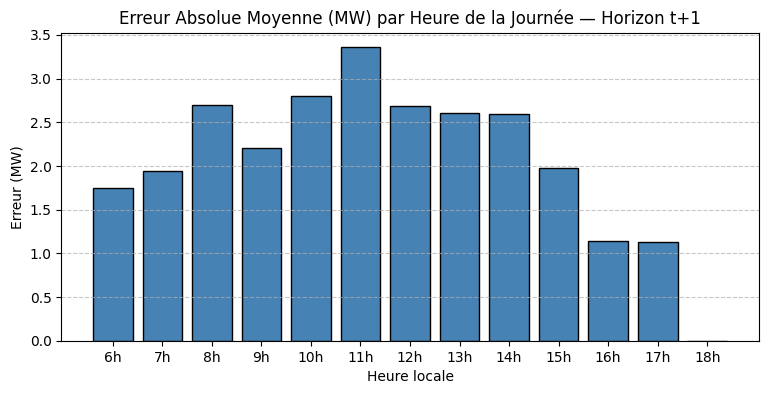

Interprétation : L'erreur est plus élevée à midi (10h-13h) car la puissance injectée est maximale (jusqu'à 50 MW), alors qu'elle est faible au lever et coucher du soleil.


In [13]:
# 7. Analyse des erreurs par heure de la journée (Horizon t+1)
t_va = T[va]
heure_cible = (t_va + pd.Timedelta(hours=1)).hour  # heure de t+1
masque_jour = J[va][:, 0]

erreur_mw = np.abs(Y[va][:, 0] - pred_va[:, 0]) * CAPACITE

# Calcul de l'erreur moyenne pour chaque heure ensoleillée (6h à 18h)
heures_uniques = range(6, 19)
erreurs_par_heure = []
for hr in heures_uniques:
    sel = (heure_cible == hr) & masque_jour
    if sel.sum() > 0:
        erreurs_par_heure.append(erreur_mw[sel].mean())
    else:
        erreurs_par_heure.append(0.0)

# Graphique à barres simple
plt.figure(figsize=(9, 4))
plt.bar([f"{hr}h" for hr in heures_uniques], erreurs_par_heure, color="steelblue", edgecolor="black")
plt.title("Erreur Absolue Moyenne (MW) par Heure de la Journée — Horizon t+1")
plt.xlabel("Heure locale")
plt.ylabel("Erreur (MW)")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

print("Interprétation : L'erreur est plus élevée à midi (10h-13h) car la puissance injectée est maximale (jusqu'à 50 MW), alors qu'elle est faible au lever et coucher du soleil.")

le modèle a plus de difficulté à prévoir la production pendant les heures où la production solaire est importante.

In [14]:
# 8. Question 2 : Comparaison des fonctions d'activation et de perte
couples = [
    ("sigmoid", "mse"),
    ("relu", "mse"),
    ("linear", "mse"),
    ("sigmoid", "mae"),
    ("sigmoid", "huber")
]

resultats_couples = []

for act, perte in couples:
    tf.random.set_seed(42)
    m = creer_mlp(47, activation=act, perte=perte)
    m.fit(X[tr], Y[tr], epochs=25, batch_size=128, verbose=0)

    p = m.predict(X[va], verbose=0)
    if act == "linear":
        p = np.clip(p, 0.0, 1.0)
    g = calculer_gain(Y[va], p, J[va])

    resultats_couples.append({
        "Activation": act,
        "Perte": perte,
        "Gain t+1 (%)": round(g[0] * 100, 1),
        "Gain moyen (%)": round(g.mean() * 100, 1)
    })

df_couples = pd.DataFrame(resultats_couples).sort_values("Gain moyen (%)", ascending=False)
print("=== Comparaison des couples (Activation, Perte) ===")
print(df_couples.to_string(index=False))

=== Comparaison des couples (Activation, Perte) ===
Activation Perte  Gain t+1 (%)  Gain moyen (%)
   sigmoid   mse          11.0       47.700001
   sigmoid huber          12.3       47.700001
      relu   mse          12.7       47.200001
    linear   mse           9.9       47.099998
   sigmoid   mae           9.6       46.200001


In [15]:
# 9. Question 3 : Étude d'ablation des groupes d'entrées
GROUPES = {
    "historique": list(range(0, 24)),
    "ciel_clair": list(range(24, 30)),
    "nebulosite": list(range(30, 36)),
    "temperature": list(range(36, 42)),
    "calendrier": list(range(42, 46)),
    "nettoyage": [46]
}

resultats_ablation = []
gain_complet = gains_va.mean() * 100
resultats_ablation.append({"Groupe Retiré": "Aucun (Modèle Complet)", "Gain moyen (%)": round(gain_complet, 1), "Perte (pts)": 0.0})

# Ablation groupe par groupe
for nom, colonnes in GROUPES.items():
    tf.random.set_seed(42)
    # On garde toutes les colonnes SAUF celles du groupe
    garder = [col for col in range(47) if col not in colonnes]

    m_abl = creer_mlp(len(garder), activation="sigmoid", perte="mse")
    m_abl.fit(X[tr][:, garder], Y[tr], epochs=25, batch_size=128, verbose=0)

    p_abl = m_abl.predict(X[va][:, garder], verbose=0)
    g_abl = calculer_gain(Y[va], p_abl, J[va]).mean() * 100

    resultats_ablation.append({
        "Groupe Retiré": f"Sans {nom}",
        "Gain moyen (%)": round(g_abl, 1),
        "Perte (pts)": round(gain_complet - g_abl, 1)
    })

df_ablation = pd.DataFrame(resultats_ablation).sort_values("Gain moyen (%)", ascending=False)
print("=== Tableau d'Ablation des Groupes d'Entrées ===")
print(df_ablation.to_string(index=False))

=== Tableau d'Ablation des Groupes d'Entrées ===
         Groupe Retiré  Gain moyen (%)  Perte (pts)
Aucun (Modèle Complet)       48.200001          0.0
        Sans nettoyage       47.900002          0.2
       Sans calendrier       47.799999          0.4
       Sans ciel_clair       47.500000          0.7
      Sans temperature       47.099998          1.1
       Sans historique       38.900002          9.3
       Sans nebulosite       32.500000         15.6


In [16]:
# 10. Question 4 : Régularisation (Dropout et EarlyStopping)
def creer_mlp_regularise(dropout_rate=0.1):
    entree = keras.Input(shape=(47,))
    x = layers.Dense(64, activation="relu")(entree)
    if dropout_rate > 0:
        x = layers.Dropout(dropout_rate)(x)
    x = layers.Dense(32, activation="relu")(x)
    if dropout_rate > 0:
        x = layers.Dropout(dropout_rate)(x)
    sortie = layers.Dense(H, activation="sigmoid")(x)

    modele = keras.Model(inputs=entree, outputs=sortie)
    modele.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    return modele

# Entraînement avec EarlyStopping
tf.random.set_seed(42)
mlp_reg = creer_mlp_regularise(dropout_rate=0.1)

# Arrêt précoce : si val_loss ne s'améliore plus pendant 8 époques, on s'arrête
arret_precoce = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)

mlp_reg.fit(
    X[tr], Y[tr],
    epochs=50,
    batch_size=128,
    validation_data=(X[va], Y[va]),
    callbacks=[arret_precoce],
    verbose=1
)

pred_reg_va = mlp_reg.predict(X[va], verbose=0)
gain_reg_va = calculer_gain(Y[va], pred_reg_va, J[va])
print(f"Gain moyen avec Dropout (0.1) + EarlyStopping : {gain_reg_va.mean()*100:.1f} %")

Epoch 1/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 0.0445 - val_loss: 0.0074
Epoch 2/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0124 - val_loss: 0.0062
Epoch 3/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0107 - val_loss: 0.0058
Epoch 4/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0098 - val_loss: 0.0055
Epoch 5/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0090 - val_loss: 0.0052
Epoch 6/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0087 - val_loss: 0.0052
Epoch 7/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0083 - val_loss: 0.0051
Epoch 8/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0080 - val_loss: 0.0050
Epoch 9/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0079 - val_loss: 0.0049
Epoch 10/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0076 - val_loss: 0.0049
Epoch 11/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0075 - val_loss: 0.0049
Epoch 12/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/ste

BILAN FINAL DU CAHIER DES CHARGES SUR LE TEST (2025) :
1. Gain à t+1        : 10.2 %   (Cible >= 12 %)  -> NON
2. Gain moyen (6h)   : 50.9 %   (Cible >= 30 %)  -> ATTEINTE
3. Taille du modèle  : 0.09 Mo  (Cible <= 5 Mo)  -> CONFORME


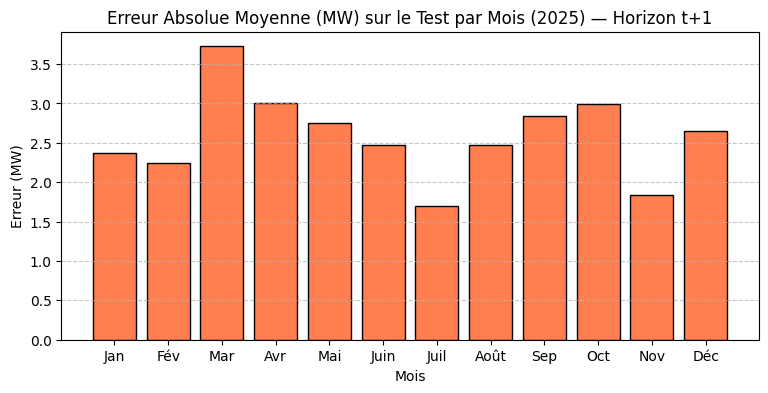

In [17]:
# 11. Évaluation finale sur l'Ensemble de Test (Année 2025)
# Attention : l'ensemble de test n'est utilisé qu'une seule fois à la fin !

# 1. Sauvegarde pour vérifier la contrainte de taille (<= 5 Mo)
mlp_reg.save("modele_solaire_jalon1.keras")
taille_mo = os.path.getsize("modele_solaire_jalon1.keras") / (1024 * 1024)

# 2. Prédictions sur le test
pred_te = mlp_reg.predict(X[te], verbose=0)
ref_pi_te = ref_pi[te]
gain_te = calculer_gain(Y[te], pred_te, J[te], ref_pred=ref_pi_te)

print("=" * 60)
print("BILAN FINAL DU CAHIER DES CHARGES SUR LE TEST (2025) :")
print(f"1. Gain à t+1        : {gain_te[0]*100:.1f} %   (Cible >= 12 %)  -> {'ATTEINTE' if gain_te[0] >= 0.12 else 'NON'}")
print(f"2. Gain moyen (6h)   : {gain_te.mean()*100:.1f} %   (Cible >= 30 %)  -> {'ATTEINTE' if gain_te.mean() >= 0.30 else 'NON'}")
print(f"3. Taille du modèle  : {taille_mo:.2f} Mo  (Cible <= 5 Mo)  -> {'CONFORME' if taille_mo <= 5 else 'NON'}")
print("=" * 60)

# Graphique des erreurs par mois sur le test 2025
t_te = T[te]
mois_te = t_te.month
err_test_mw = np.abs(Y[te][:, 0] - pred_te[:, 0]) * CAPACITE
masque_jour_te = J[te][:, 0]

erreurs_mois = []
for m in range(1, 13):
    sel = (mois_te == m) & masque_jour_te
    erreurs_mois.append(err_test_mw[sel].mean())

plt.figure(figsize=(9, 4))
plt.bar(range(1, 13), erreurs_mois, color="coral", edgecolor="black")
plt.title("Erreur Absolue Moyenne (MW) sur le Test par Mois (2025) — Horizon t+1")
plt.xlabel("Mois")
plt.ylabel("Erreur (MW)")
plt.xticks(range(1, 13), ["Jan", "Fév", "Mar", "Avr", "Mai", "Juin", "Juil", "Août", "Sep", "Oct", "Nov", "Déc"])
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

In [18]:
# 12. Vérifications Théoriques (Calculs & Vérifications)

print("--- QUESTION THÉORIQUE 1 : Décompte des paramètres ---")
# Couche 1 : 47 entrées * 64 poids + 64 biais = 3072
# Couche 2 : 64 entrées * 32 poids + 32 biais = 2080
# Sortie   : 32 entrées * 6 poids + 6 biais   = 198
total_theorique = (47 * 64 + 64) + (64 * 32 + 32) + (32 * 6 + 6)
total_modele = mlp_ref.count_params()
print(f"Calcul théorique : {total_theorique} paramètres")
print(f"Comptage Keras   : {total_modele} paramètres")
print(f"Concordance      : {'OK' if total_theorique == total_modele else 'Erreur'}\n")

print("--- QUESTION THÉORIQUE 2 : Persistance intelligente à 11h ---")
# Formule GHI_cs(alpha) = 1098 * sin(alpha) * exp(-0.057 / sin(alpha))
alpha_10 = 40.0
alpha_11 = 50.0
ghi_10 = float(ciel_clair(np.array([alpha_10]))[0])
ghi_11 = float(ciel_clair(np.array([alpha_11]))[0])
p_10 = 30.0 # 30 MW
p_11_pred = p_10 * (ghi_11 / ghi_10)

print(f"GHI ciel clair à 10h (40°) : {ghi_10:.2f} W/m²")
print(f"GHI ciel clair à 11h (50°) : {ghi_11:.2f} W/m²")
print(f"Prévision pour 11h          : {p_11_pred:.2f} MW (Calcul théorique attendu : ~36.27 MW)\n")

print("--- QUESTION THÉORIQUE 3 : Dérivée de la sigmoïde à 0.99 ---")
# sigma'(z) = sigma(z) * (1 - sigma(z))
s = 0.99
derivee = s * (1.0 - s)
print(f"Dérivée en s = 0.99 : {derivee:.4f}")
print("Conséquence sur l'écrêtage : La dérivée devient quasiment nulle (0.0099).")
print("Cela provoque un gradient évanescent : le réseau n'apprend presque plus lors des heures d'écrêtage (50 MW en été).")

--- QUESTION THÉORIQUE 1 : Décompte des paramètres ---
Calcul théorique : 5350 paramètres
Comptage Keras   : 5350 paramètres
Concordance      : OK

--- QUESTION THÉORIQUE 2 : Persistance intelligente à 11h ---
GHI ciel clair à 10h (40°) : 645.89 W/m²
GHI ciel clair à 11h (50°) : 780.80 W/m²
Prévision pour 11h          : 36.27 MW (Calcul théorique attendu : ~36.27 MW)

--- QUESTION THÉORIQUE 3 : Dérivée de la sigmoïde à 0.99 ---
Dérivée en s = 0.99 : 0.0099
Conséquence sur l'écrêtage : La dérivée devient quasiment nulle (0.0099).
Cela provoque un gradient évanescent : le réseau n'apprend presque plus lors des heures d'écrêtage (50 MW en été).
